<a href="https://colab.research.google.com/github/Pedro-Veiga0/HipMoS4C/blob/main/Grid_Search_Anomalib.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install Anomalib with full dependencies
!pip install --quiet "anomalib[full]"

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 5.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 5.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 5.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 73.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 859.9/859.9 kB 47.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.5/231.5 kB 26.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 246.1/246.1 kB 29.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 81.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 68.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 142.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 123.9 MB/s eta 0:00:00
 

# Wide_Resnet50_V2 Benchmark

In [ ]:
import sys
import gc
import datetime
import time
from pathlib import Path
from google.colab import drive
import pandas as pd
import torch

from anomalib import TaskType
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Patchcore
from anomalib.metrics import AUROC, F1Score, Evaluator, PRO, AUPRO, AUPIMO

torch.set_float32_matmul_precision('high')

# Mount Google Drive
drive.mount('/content/drive', force_remount=False)
drive_dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_wide_resnet50.xlsx")
excel_log_path.parent.mkdir(parents=True, exist_ok=True)

# 2. Experiment Configurations
OBJECT_CATEGORIES = [
    "bottle", "cable", "capsule", "hazelnut", "metal_nut",
    "pill", "screw", "toothbrush", "transistor", "zipper"
]
TEXTURE_CATEGORIES = ["carpet", "grid", "leather", "tile", "wood"]
ALL_CATEGORIES = OBJECT_CATEGORIES + TEXTURE_CATEGORIES

BACKBONE = "wide_resnet50_v2"
CORESET_RATIO = 0.1
KNN_NEIGHBORS = 9
# pool_size = 1
layers = ["layer2", "layer3"]

def estimate_memory_bank_size(model):
    """Estimate the disk size of the memory bank in Megabytes (MB)."""
    if hasattr(model, "model") and hasattr(model.model, "memory_bank"):
        num_elements = model.model.memory_bank.numel()
        element_size = model.model.memory_bank.element_size() # size in bytes
        size_mb = (num_elements * element_size) / (1024 * 1024)
        return size_mb
    return 0.0


for category in ALL_CATEGORIES:
  gc.collect()
  torch.cuda.empty_cache()

  metrics = [
        AUROC(prefix="image_", fields=["pred_score", "gt_label"]),
        AUPRO(fields=["anomaly_map", "gt_mask"]),
        AUROC(prefix="pixel_", fields=["anomaly_map", "gt_mask"]),
        AUPIMO()
  ]

  evaluator = Evaluator(test_metrics=metrics)

  # 3. DataModule Configuration
  datamodule = MVTecAD(
      root=drive_dataset_root,
      category=category,
      train_batch_size=32,
      eval_batch_size=32,
      num_workers=4,
  )

  # 4. PatchCore Model Configuration
  model = Patchcore(
      backbone=BACKBONE,
      layers=layers,
      coreset_sampling_ratio=CORESET_RATIO,
      num_neighbors=KNN_NEIGHBORS,
      evaluator=evaluator,
  )

  # 5. Engine Setup
  engine = Engine(
      default_root_dir="./results",
      accelerator="gpu",
      devices=1,
      enable_progress_bar=False,
  )

  start_time = time.perf_counter()

  # 6. Fit and Test
  print(f"\nFitting PatchCore ({BACKBONE}) on {category} with coreset {CORESET_RATIO}...")
  engine.fit(datamodule=datamodule, model=model)

  training_duration = round(time.perf_counter() - start_time, 2)
  print(f"Training completed in: {training_duration}s ({training_duration / 60:.2f} min)")

  print("Running test evaluation...")
  test_results_raw = engine.test(datamodule=datamodule, model=model)

  test_results = test_results_raw[0] if test_results_raw else {}

  # 7. Extract Metric Scores
  image_auroc = test_results.get("image_AUROC", test_results.get("image_auroc", 0.0))
  pixel_auroc = test_results.get("pixel_AUROC", test_results.get("pixel_auroc", 0.0))
  aupro = test_results.get("AUPRO", test_results.get("aupro", 0.0))
  aupimo = test_results.get("AUPIMO", test_results.get("aupimo", 0.0))
  memory_bank_size_mb = estimate_memory_bank_size(model)

  new_record = {
      "Timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
      "Training_Time_Sec": training_duration,
      "Category": category + " texture" if category in TEXTURE_CATEGORIES else category + " object",
      "Backbone": BACKBONE,
      "Layers_Used": ", ".join(layers),
      # "Pool_Size": pool_size,
      "Coreset_Ratio": CORESET_RATIO,
      "KNN": KNN_NEIGHBORS,
      "Image_AUROC": round(float(image_auroc), 4),
      "Pixel_AUROC": round(float(pixel_auroc), 4),
      "AUPRO": round(float(aupro), 4),
      "AUPIMO": round(float(aupimo), 4),
      "Memory_Bank_MB": round(float(memory_bank_size_mb), 2),
  }

  new_df = pd.DataFrame([new_record])

  # 8. Append to Persistent Excel Spreadsheet
  if excel_log_path.exists():
      existing_df = pd.read_excel(excel_log_path)
      updated_df = pd.concat([existing_df, new_df], ignore_index=True)
  else:
      updated_df = new_df

  updated_df.to_excel(excel_log_path, index=False)
  print(f"\nExperiment successfully logged to: {excel_log_path}")

  # Display current logged history
  print("\n========== EXPERIMENT LOG HISTORY ==========")
  print(updated_df.to_string(index=False))

# Grid Search Vit Small (Seed)

In [ ]:
import sys
import gc
import datetime
import time
import random
from pathlib import Path
from google.colab import drive
import pandas as pd
import numpy as np
import torch
from lightning.pytorch import seed_everything

from anomalib import TaskType
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Patchcore
from anomalib.metrics import AUROC, F1Score, Evaluator, PRO, AUPRO, AUPIMO

torch.set_float32_matmul_precision('high')

# SEEDS: 42, 108, 3110
RUN_SEED = 3110

def set_reproducible_seed(seed=3110):
    # 1. PyTorch Lightning utility sets seeds for Python random, numpy, and pytorch (both CPU and CUDA)
    seed_everything(seed, workers=True)

    # 2. Additional PyTorch reproducibility flags
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    print(f"Global seed set to: {seed}")

# Call the helper at the very beginning of your execution
set_reproducible_seed(RUN_SEED)

# Mount Google Drive
drive.mount('/content/drive', force_remount=False)
drive_dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_gridsearch_vit_small_coreset.xlsx")
excel_log_path.parent.mkdir(parents=True, exist_ok=True)

# 2. Experiment Configurations
OBJECT_CATEGORIES = [
    "bottle", "cable", "capsule", "hazelnut", "metal_nut",
    "pill", "screw", "toothbrush", "transistor", "zipper"
]
TEXTURE_CATEGORIES = ["carpet", "grid", "leather", "tile", "wood"]
ALL_CATEGORIES = OBJECT_CATEGORIES + TEXTURE_CATEGORIES

BACKBONE = "vit_small_patch16_dinov3"
CORESET_RATIO = [0.01, 0.02, 0.05, 0.10, 0.20, 0.40]
KNN_NEIGHBORS = 9
pool_size = 1
layer_experiments = [["blocks.7"], ["blocks.11"], ["blocks.1", "blocks.6"], ["blocks.2", "blocks.10"]]

def estimate_memory_bank_size(model):
    """Estimate the disk size of the memory bank in Megabytes (MB)."""
    if hasattr(model, "model") and hasattr(model.model, "memory_bank"):
        num_elements = model.model.memory_bank.numel()
        element_size = model.model.memory_bank.element_size() # size in bytes
        size_mb = (num_elements * element_size) / (1024 * 1024)
        return size_mb
    return 0.0

for category in ALL_CATEGORIES:
  for coreset_ratio in CORESET_RATIO:
    for blocks in layer_experiments:
      gc.collect()
      torch.cuda.empty_cache()

      metrics = [
            AUROC(prefix="image_", fields=["pred_score", "gt_label"]),
            AUPRO(fields=["anomaly_map", "gt_mask"]),
            AUROC(prefix="pixel_", fields=["anomaly_map", "gt_mask"]),
            AUPIMO()
      ]

      evaluator = Evaluator(test_metrics=metrics)

      # 3. DataModule Configuration
      datamodule = MVTecAD(
          root=drive_dataset_root,
          category=category,
          train_batch_size=32,
          eval_batch_size=32,
          num_workers=4,
      )

      # 4. PatchCore Model Configuration
      model = Patchcore(
          backbone=BACKBONE,
          layers=blocks,
          coreset_sampling_ratio=coreset_ratio,
          num_neighbors=KNN_NEIGHBORS,
          evaluator=evaluator,
      )

      # Apply Feature Pooler override
      if hasattr(model, "model") and hasattr(model.model, "feature_pooler"):
          padding = pool_size // 2
          model.model.feature_pooler = torch.nn.AvgPool2d(kernel_size=pool_size, stride=1, padding=padding)
          print(f"Successfully updated feature_pooler: AvgPool2d(kernel_size={pool_size}, stride=1, padding={padding})")
      else:
          print("Warning: could not locate model.model.feature_pooler. Using default pooler.")

      # 5. Engine Setup
      engine = Engine(
          default_root_dir="./results",
          accelerator="gpu",
          devices=1,
          enable_progress_bar=False,
      )

      start_time = time.perf_counter()

      # 6. Fit and Test
      print(f"\nFitting PatchCore ({BACKBONE}) on {category} with coreset {coreset_ratio}...")
      engine.fit(datamodule=datamodule, model=model)

      training_duration = round(time.perf_counter() - start_time, 2)
      print(f"Training completed in: {training_duration}s ({training_duration / 60:.2f} min)")

      print("Running test evaluation...")
      test_results_raw = engine.test(datamodule=datamodule, model=model)

      test_results = test_results_raw[0] if test_results_raw else {}

      # 7. Extract Metric Scores
      image_auroc = test_results.get("image_AUROC", test_results.get("image_auroc", 0.0))
      pixel_auroc = test_results.get("pixel_AUROC", test_results.get("pixel_auroc", 0.0))
      aupro = test_results.get("AUPRO", test_results.get("aupro", 0.0))
      aupimo = test_results.get("AUPIMO", test_results.get("aupimo", 0.0))
      memory_bank_size_mb = estimate_memory_bank_size(model)

      new_record = {
          "Timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
          "Training_Time_Sec": training_duration,
          "Category": category + " texture" if category in TEXTURE_CATEGORIES else category + " object",
          "Backbone": BACKBONE,
          "Layers_Used": ", ".join(blocks),
          "Pool_Size": pool_size,
          "Coreset_Ratio": coreset_ratio,
          "KNN": KNN_NEIGHBORS,
          "Seed": RUN_SEED,
          "Image_AUROC": round(float(image_auroc), 4),
          "Pixel_AUROC": round(float(pixel_auroc), 4),
          "AUPRO": round(float(aupro), 4),
          "AUPIMO": round(float(aupimo), 4),
          "Memory_Bank_MB": round(float(memory_bank_size_mb), 2),
      }

      new_df = pd.DataFrame([new_record])

      # 8. Append to Persistent Excel Spreadsheet
      if excel_log_path.exists():
          existing_df = pd.read_excel(excel_log_path)
          updated_df = pd.concat([existing_df, new_df], ignore_index=True)
      else:
          updated_df = new_df

      updated_df.to_excel(excel_log_path, index=False)
      print(f"\nExperiment successfully logged to: {excel_log_path}")

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/anomalib/models/image/dinomaly/components/layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention
INFO: Seed set to 3110
INFO:lightning.fabric.utilities.seed:Seed set to 3110


Global seed set to: 3110
Mounted at /content/drive


model.safetensors: reconstructing file:   0%|          |  0.00B / 86.4MB            

model.safetensors: downloading bytes:           |  0.00B            

INFO:lightning_fabric.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:lightning_fabric.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:lightning_fabric.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


...

Trainable params: 21.6 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 21.6 M                                                                                               
Total estimated model params size (MB): 86.348                                                                     
Modules in train mode: 19                                                                                          
Modules in eval mode: 253                                                                                          
Total FLOPs: 0

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loops/fit_loop.py:538: Found 253 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.
Selecting Coreset Indices.: 100%|██████████| 25291/25291 [00:22<00:00, 1133.29it/s]
INFO:lightning_fabric.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=1` reached.
INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training completed in: 29.54s (0.49 min)
Running test evaluation...


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          AUPIMO           │    0.10303863245590493    │
│           AUPRO           │    0.9450807571411133     │
│        image_AUROC        │    0.9710526466369629     │
│        pixel_AUROC        │    0.9659014940261841     │
└───────────────────────────┴───────────────────────────┘


Experiment successfully logged to: /content/drive/MyDrive/anomalib_experiments/patchcore_gridsearch_vit_small_coreset.xlsx


# Data Viz ViT Small

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

Mounted at /content/drive


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


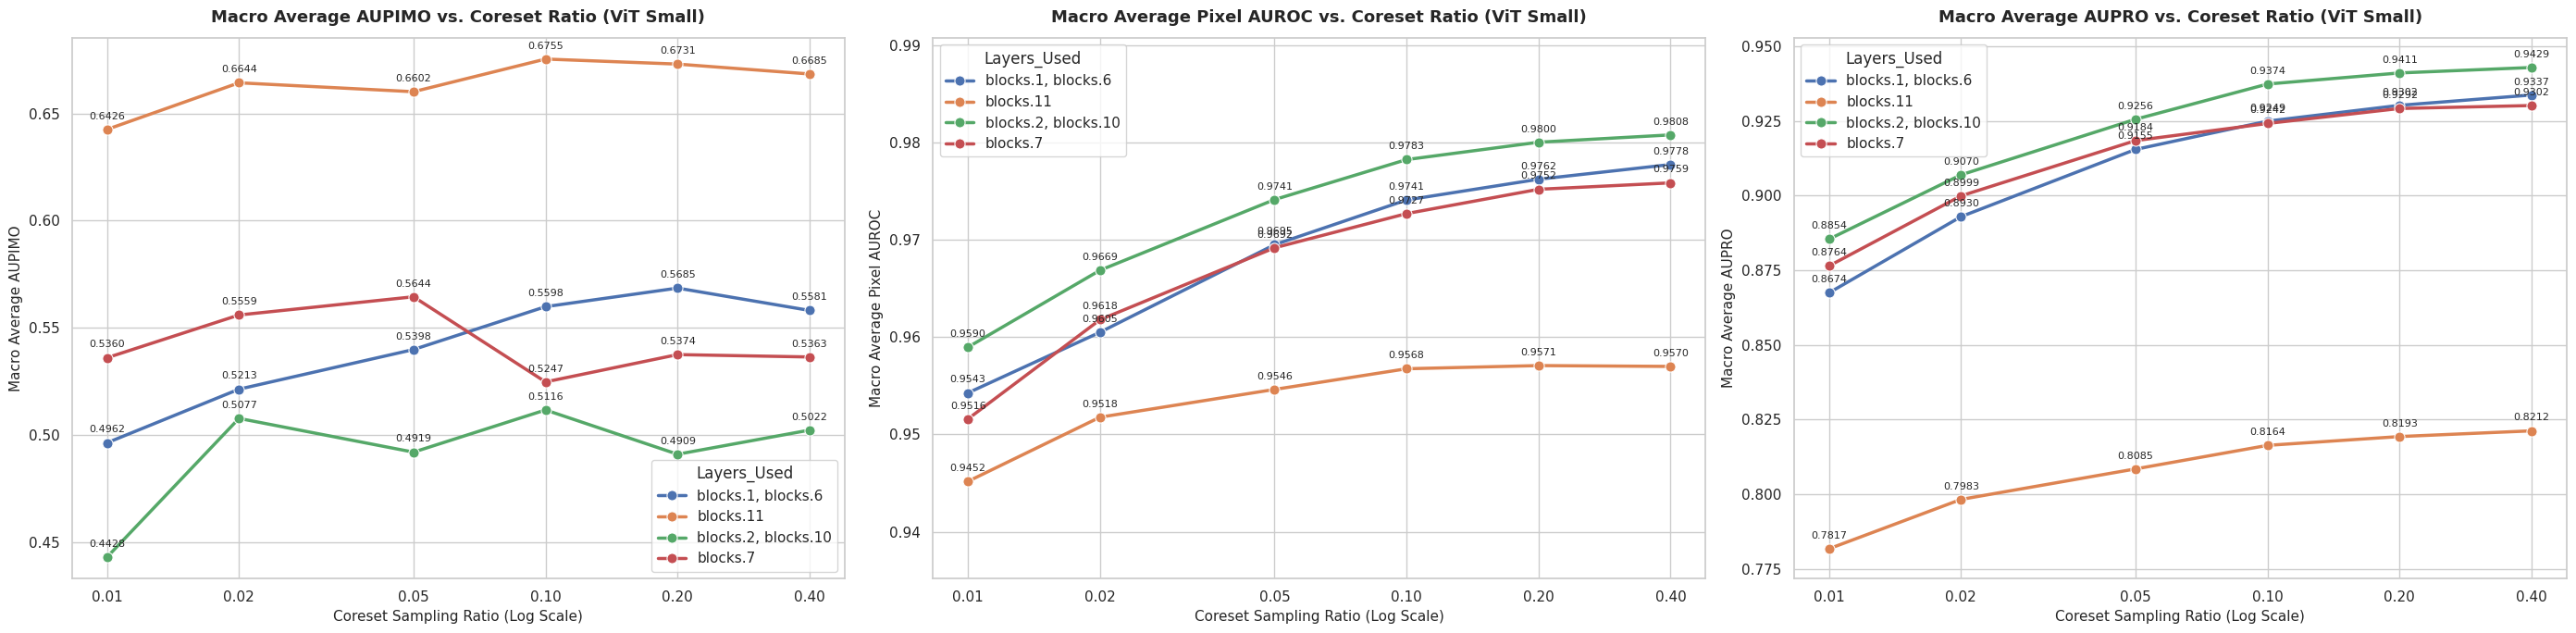

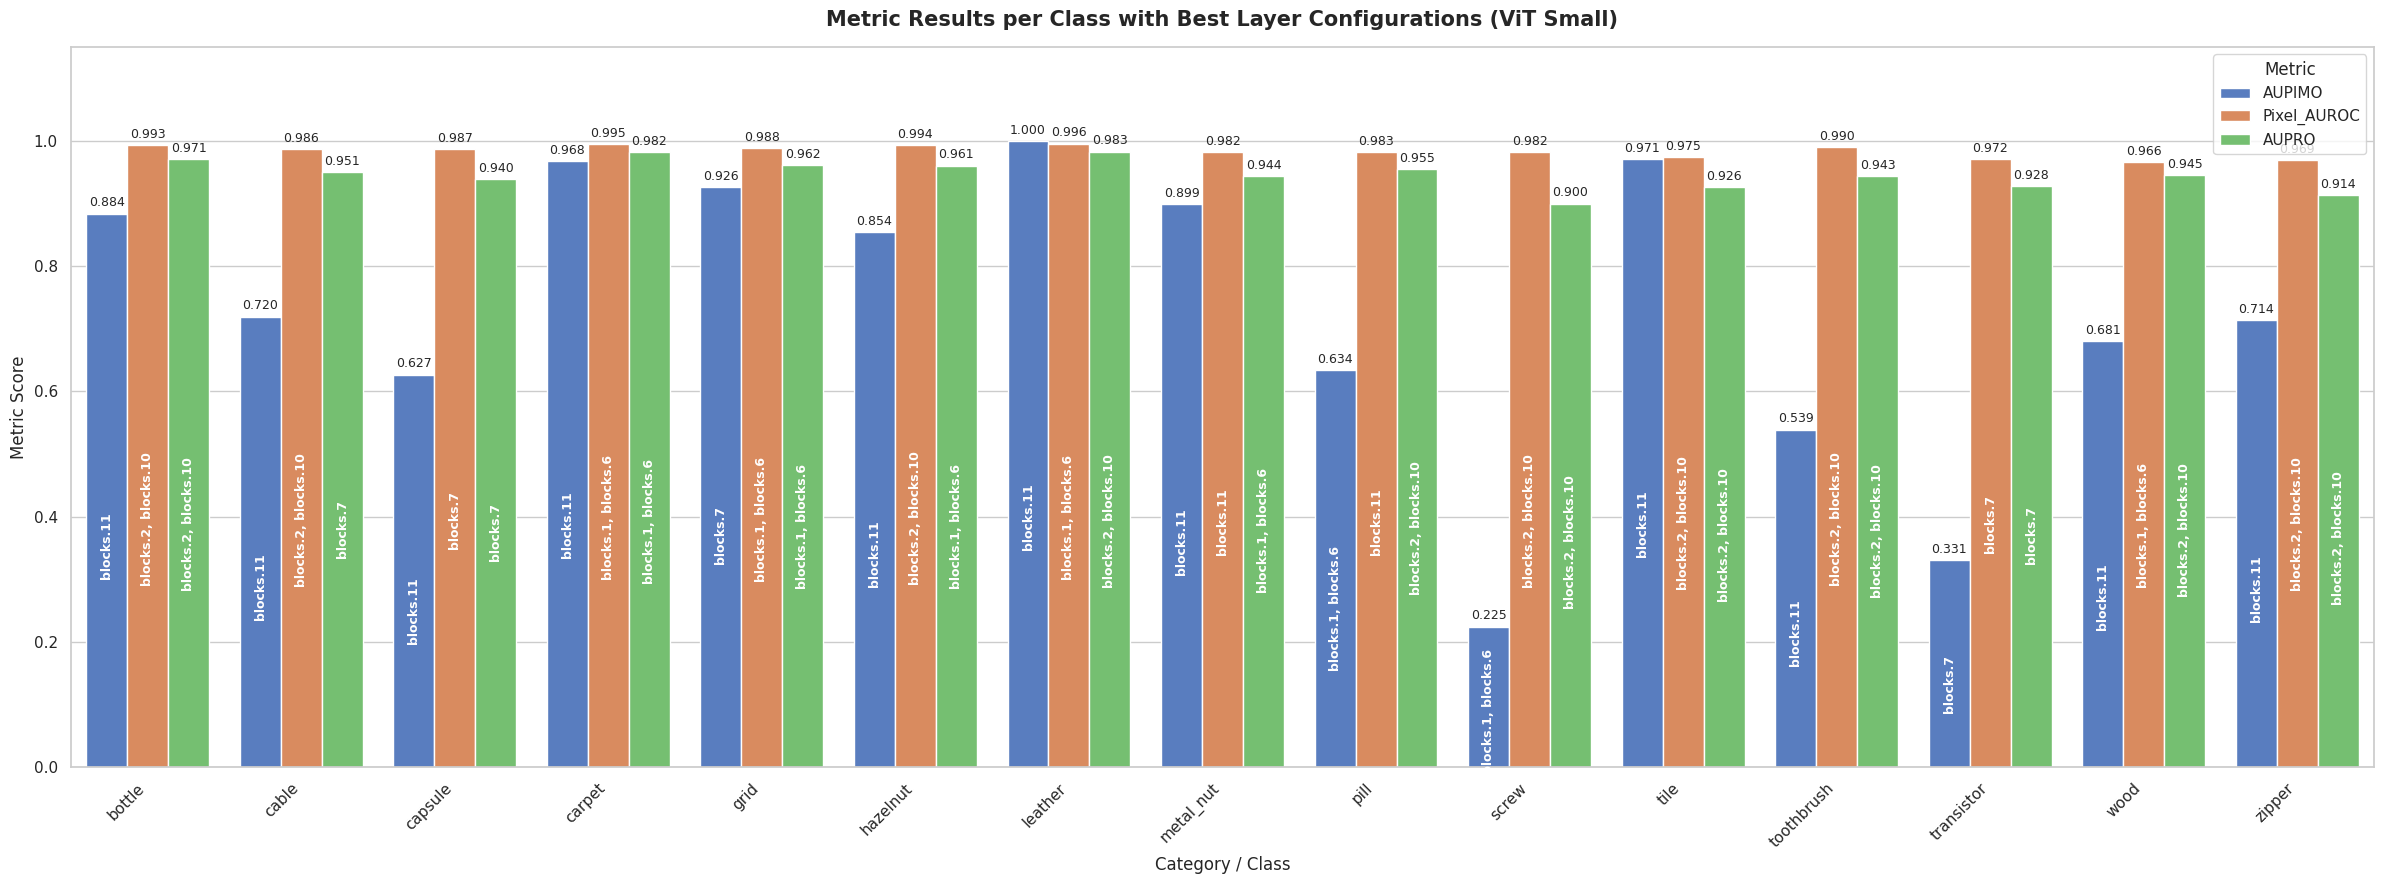

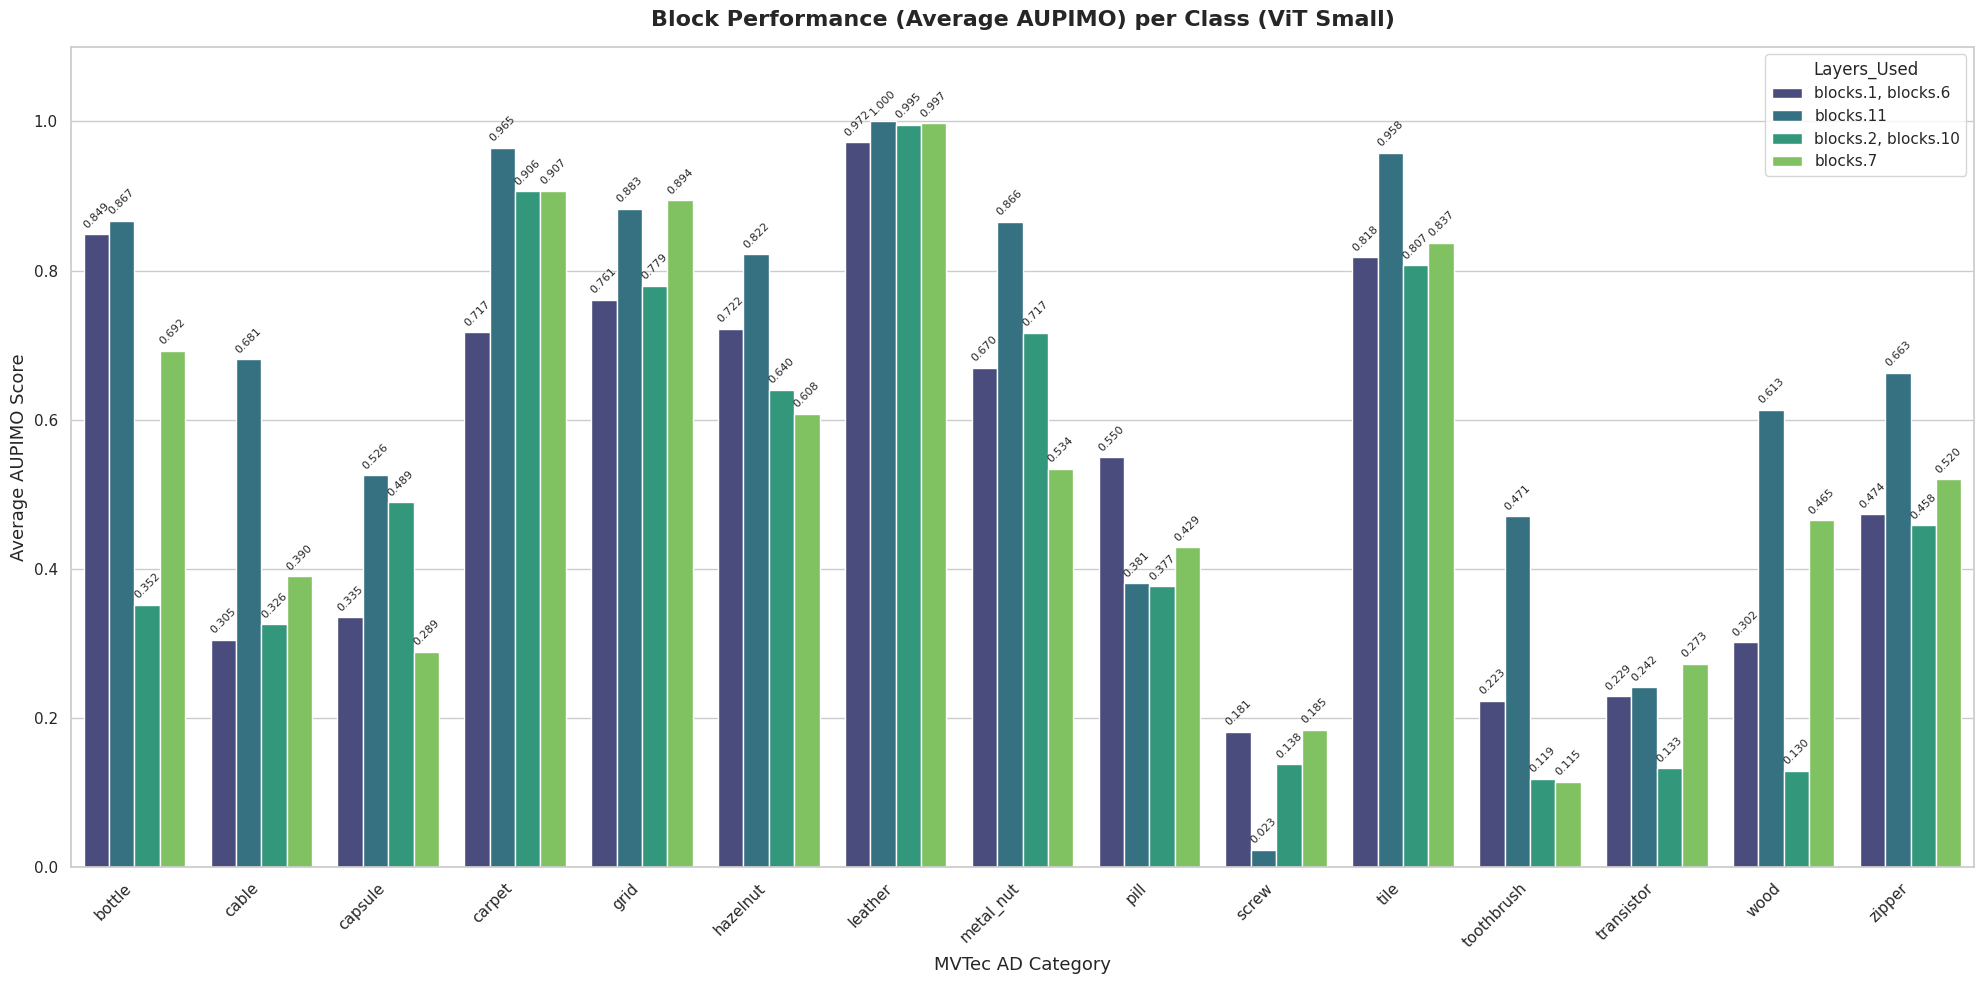

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive', force_remount=False)

# 2. Path to the ViT Base dataset
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_gridsearch_vit_small_coreset.xlsx")
if not excel_log_path.exists():
    raise FileNotFoundError(f"Could not find the log file at: {excel_log_path}")

# 3. Load dataset
df = pd.read_excel(excel_log_path)

# 4. Standardize and clean category names
category_col = "Category" if "Category" in df.columns else "Class"
df["Clean_Category"] = df[category_col].astype(str).str.replace(" texture", "").str.replace(" object", "")

# 5. Extract latest runs
group_cols = ["Clean_Category", "Coreset_Ratio", "Layers_Used"] if "Coreset_Ratio" in df.columns else ["Clean_Category", "Layers_Used"]
latest_runs = df.sort_values("Timestamp").groupby(group_cols).last().reset_index() if "Timestamp" in df.columns else df

# 6. Plot 1: Macro Average vs Coreset Ratio (if multiple coreset ratios exist)
if "Coreset_Ratio" in latest_runs.columns and latest_runs["Coreset_Ratio"].nunique() > 1:
    macro_summary = latest_runs.groupby(["Coreset_Ratio", "Layers_Used"])[["AUPIMO", "Pixel_AUROC", "AUPRO"]].mean().reset_index()
    sns.set_theme(style="whitegrid")
    metrics_to_plot = [
        ("AUPIMO", "Macro Average AUPIMO"),
        ("Pixel_AUROC", "Macro Average Pixel AUROC"),
        ("AUPRO", "Macro Average AUPRO")
    ]
    fig, axes = plt.subplots(1, 3, figsize=(28, 7))
    for idx, (col_name, label) in enumerate(metrics_to_plot):
        ax = axes[idx]
        sns.lineplot(data=macro_summary, x="Coreset_Ratio", y=col_name, hue="Layers_Used", marker="o", linewidth=2.5, markersize=8, ax=ax)
        ax.set_title(f"{label} vs. Coreset Ratio (ViT Small)", fontsize=13, fontweight="bold", pad=12)
        ax.set_xlabel("Coreset Sampling Ratio (Log Scale)", fontsize=11)
        ax.set_ylabel(label, fontsize=11)
        ax.set_xscale('log')
        ratios = sorted(macro_summary["Coreset_Ratio"].unique())
        ax.set_xticks(ratios)
        ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
        min_val, max_val = macro_summary[col_name].min(), macro_summary[col_name].max()
        ax.set_ylim(min_val - 0.01, min(max_val + 0.01, 1.0))
        for layers in macro_summary["Layers_Used"].unique():
            subset_df = macro_summary[macro_summary["Layers_Used"] == layers]
            for x, y in zip(subset_df["Coreset_Ratio"], subset_df[col_name]):
                ax.annotate(f"{y:.4f}", (x, y), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping Coreset Ratio line plot because only one Coreset Ratio was used or column is missing.")

# 7. Plot 2: Best Configurations Per Class
best_configs = {}
for metric in ["AUPIMO", "Pixel_AUROC", "AUPRO"]:
    if metric in latest_runs.columns:
        idx_max = latest_runs.groupby("Clean_Category")[metric].idxmax()
        best_rows = latest_runs.loc[idx_max]
        for _, row in best_rows.iterrows():
            best_configs[(row["Clean_Category"], metric)] = {
                "score": row[metric],
                "block": row["Layers_Used"]
            }

class_summary = latest_runs.groupby("Clean_Category")[["AUPIMO", "Pixel_AUROC", "AUPRO"]].max().reset_index()
melted_class = class_summary.melt(id_vars="Clean_Category", value_vars=["AUPIMO", "Pixel_AUROC", "AUPRO"], var_name="Metric", value_name="Score")

plt.figure(figsize=(24, 9))
ax = sns.barplot(data=melted_class, x="Clean_Category", y="Score", hue="Metric", palette="muted")
plt.title("Metric Results per Class with Best Layer Configurations (ViT Small)", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Category / Class", fontsize=12)
plt.ylabel("Metric Score", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.ylim(0.0, 1.15)

categories = sorted(melted_class["Clean_Category"].unique())
metrics = ["AUPIMO", "Pixel_AUROC", "AUPRO"]
num_categories = len(categories)

for i, p in enumerate(ax.patches):
    height = p.get_height()
    if height > 0:
        metric_idx = i // num_categories
        category_idx = i % num_categories
        metric_name = metrics[metric_idx]
        category_name = categories[category_idx]
        best_info = best_configs.get((category_name, metric_name), {"score": height, "block": "N/A"})
        block_label = best_info["block"]
        ax.annotate(f"{height:.3f}", (p.get_x() + p.get_width() / 2., height), ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')
        ax.annotate(str(block_label), (p.get_x() + p.get_width() / 2., height * 0.40), ha='center', va='center', color='white', fontsize=9, fontweight='bold', rotation=90)

plt.tight_layout()
plt.show()

# 8. Plot 3: Block Performance (Average AUPIMO) per Class
if "AUPIMO" in latest_runs.columns:
    block_perf = latest_runs.groupby(["Clean_Category", "Layers_Used"])["AUPIMO"].mean().reset_index()
    plt.figure(figsize=(20, 10))
    ax = sns.barplot(data=block_perf, x="Clean_Category", y="AUPIMO", hue="Layers_Used", palette="viridis")
    plt.title("Block Performance (Average AUPIMO) per Class (ViT Small)", fontsize=16, fontweight="bold", pad=15)
    plt.xlabel("MVTec AD Category", fontsize=13)
    plt.ylabel("Average AUPIMO Score", fontsize=13)
    plt.xticks(rotation=45, ha="right")
    plt.ylim(0.0, 1.1)
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.annotate(f"{height:.3f}", (p.get_x() + p.get_width() / 2., height), ha='center', va='bottom', fontsize=8, xytext=(0, 3), textcoords='offset points', rotation=45)
    plt.tight_layout()
    plt.show()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


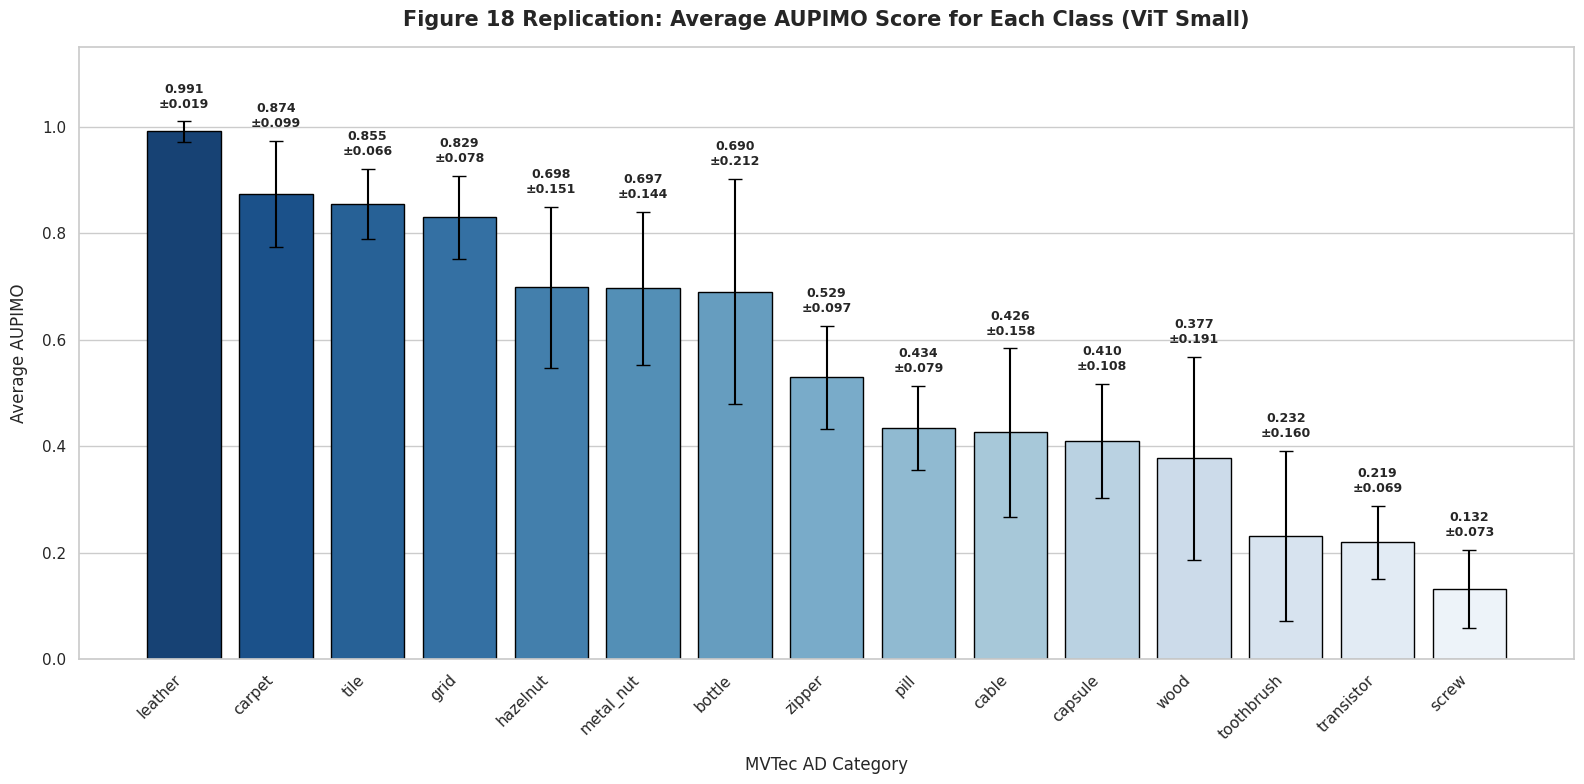

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import drive

# 1. Mount Google Drive safely
drive.mount('/content/drive', force_remount=False)

# 2. Path to the ViT-Small dataset
excel_log_path_small = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_gridsearch_vit_small_coreset.xlsx")
if not excel_log_path_small.exists():
    raise FileNotFoundError(f"Could not find the log file at: {excel_log_path_small}")

# 3. Load dataset
df_small = pd.read_excel(excel_log_path_small)

# 4. Standardize and clean category names
df_small["Clean_Category"] = df_small["Category"].str.replace(" texture", "").str.replace(" object", "")

# 5. Extract latest runs
latest_runs_small = df_small.sort_values("Timestamp").groupby(["Clean_Category", "Coreset_Ratio", "Layers_Used"]).last().reset_index()

# 6. Calculate Average AUPIMO and Std Dev for each category across all configurations
class_aupimo_stats_small = latest_runs_small.groupby("Clean_Category")["AUPIMO"].agg(Mean_AUPIMO="mean", Std_AUPIMO="std").reset_index()
class_aupimo_stats_small = class_aupimo_stats_small.sort_values(by="Mean_AUPIMO", ascending=False)

# 7. Create Visualization mimicking Figure 18 style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 8))

# Create bar plot and capture the bar positions
ax = sns.barplot(
    data=class_aupimo_stats_small,
    x="Clean_Category",
    y="Mean_AUPIMO",
    hue="Clean_Category",
    palette="Blues_r",
    edgecolor="black",
    legend=False
)

# Add the error bars manually using errorbar to avoid shape mismatch issues
x_coords = range(len(class_aupimo_stats_small))
plt.errorbar(
    x=x_coords,
    y=class_aupimo_stats_small["Mean_AUPIMO"],
    yerr=class_aupimo_stats_small["Std_AUPIMO"],
    fmt='none',
    color='black',
    capsize=5,
    elinewidth=1.5
)

plt.title("Figure 18 Replication: Average AUPIMO Score for Each Class (ViT Small)", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("MVTec AD Category", fontsize=12, labelpad=10)
plt.ylabel("Average AUPIMO", fontsize=12, labelpad=10)
plt.xticks(ticks=x_coords, labels=class_aupimo_stats_small["Clean_Category"], rotation=45, ha="right", fontsize=11)
plt.ylim(0.0, 1.15)

# Annotate the exact average score values on top of each bar
for idx, p in enumerate(ax.patches):
    height = p.get_height()
    mean_val = class_aupimo_stats_small.iloc[idx]["Mean_AUPIMO"]
    std_val = class_aupimo_stats_small.iloc[idx]["Std_AUPIMO"]
    ax.annotate(
        f"{mean_val:.3f}\n±{std_val:.3f}",
        (p.get_x() + p.get_width() / 2., max(height, mean_val + std_val) + 0.02),
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

# Grid Search ViT Base (Seed)

In [ ]:
import sys
import gc
import datetime
import time
import random
from pathlib import Path
from google.colab import drive
import pandas as pd
import numpy as np
import torch
from lightning.pytorch import seed_everything

# Restore missing imports to resolve NameError
from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import Patchcore
from anomalib.metrics import AUROC, AUPRO, AUPIMO, Evaluator

torch.set_float32_matmul_precision('high')

# Configure seed value
RUN_SEED = 3110

def set_reproducible_seed(seed=3110):
    # 1. PyTorch Lightning utility sets seeds for Python random, numpy, and pytorch (both CPU and CUDA)
    seed_everything(seed, workers=True)

    # 2. Additional PyTorch reproducibility flags
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    print(f"Global seed set to: {seed}")

# Call the helper at the very beginning of your execution
set_reproducible_seed(RUN_SEED)

# Mount Google Drive
drive.mount('/content/drive', force_remount=False)
drive_dataset_root = Path("/content/drive/MyDrive/anomalib_datasets/MVTecAD")
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_gridsearch_vit_base_coreset_copy.xlsx")
excel_log_path.parent.mkdir(parents=True, exist_ok=True)

# 2. Experiment Configurations

OBJECT_CATEGORIES = [
    "bottle", "cable", "capsule", "hazelnut", "metal_nut",
    "pill", "screw", "toothbrush", "transistor", "zipper"
]
TEXTURE_CATEGORIES = ["carpet", "grid", "leather", "tile", "wood"]
ALL_CATEGORIES = OBJECT_CATEGORIES + TEXTURE_CATEGORIES

BACKBONE = "vit_base_patch16_dinov3"
CORESET_RATIO = [0.01, 0.02, 0.05, 0.10, 0.20, 0.40]
KNN_NEIGHBORS = 9
pool_size = 1
layer_experiments = [["blocks.6"], ["blocks.9"], ["blocks.0", "blocks.9"], ["blocks.1", "blocks.9"]]

def estimate_memory_bank_size(model):
    """Estimate the disk size of the memory bank in Megabytes (MB)."""
    if hasattr(model, "model") and hasattr(model.model, "memory_bank"):
        num_elements = model.model.memory_bank.numel()
        element_size = model.model.memory_bank.element_size() # size in bytes
        size_mb = (num_elements * element_size) / (1024 * 1024)
        return size_mb
    return 0.0

for category in ALL_CATEGORIES:
  for coreset_ratio in CORESET_RATIO:
    for blocks in layer_experiments:
      gc.collect()
      torch.cuda.empty_cache()

      metrics = [
            AUROC(prefix="image_", fields=["pred_score", "gt_label"]),
            AUPRO(fields=["anomaly_map", "gt_mask"]),
            AUROC(prefix="pixel_", fields=["anomaly_map", "gt_mask"]),
            AUPIMO()
      ]

      evaluator = Evaluator(test_metrics=metrics)

      # 3. DataModule Configuration
      datamodule = MVTecAD(
          root=drive_dataset_root,
          category=category,
          train_batch_size=32,
          eval_batch_size=32,
          num_workers=4,
      )

      # 4. PatchCore Model Configuration
      model = Patchcore(
          backbone=BACKBONE,
          layers=blocks,
          coreset_sampling_ratio=coreset_ratio,
          num_neighbors=KNN_NEIGHBORS,
          evaluator=evaluator,
      )

      # Apply Feature Pooler override
      if hasattr(model, "model") and hasattr(model.model, "feature_pooler"):
          padding = pool_size // 2
          model.model.feature_pooler = torch.nn.AvgPool2d(kernel_size=pool_size, stride=1, padding=padding)
          print(f"Successfully updated feature_pooler: AvgPool2d(kernel_size={pool_size}, stride=1, padding={padding})")
      else:
          print("Warning: could not locate model.model.feature_pooler. Using default pooler.")

      # 5. Engine Setup
      engine = Engine(
          default_root_dir="./results",
          accelerator="gpu",
          devices=1,
          enable_progress_bar=False,
      )

      start_time = time.perf_counter()

      # 6. Fit and Test
      print(f"\nFitting PatchCore ({BACKBONE}) on {category} with coreset {coreset_ratio}...")
      engine.fit(datamodule=datamodule, model=model)

      training_duration = round(time.perf_counter() - start_time, 2)
      print(f"Training completed in: {training_duration}s ({training_duration / 60:.2f} min)")

      print("Running test evaluation...")
      test_results_raw = engine.test(datamodule=datamodule, model=model)

      test_results = test_results_raw[0] if test_results_raw else {}

      # 7. Extract Metric Scores
      image_auroc = test_results.get("image_AUROC", test_results.get("image_auroc", 0.0))
      pixel_auroc = test_results.get("pixel_AUROC", test_results.get("pixel_auroc", 0.0))
      aupro = test_results.get("AUPRO", test_results.get("aupro", 0.0))
      aupimo = test_results.get("AUPIMO", test_results.get("aupimo", 0.0))
      memory_bank_size_mb = estimate_memory_bank_size(model)

      new_record = {
          "Timestamp": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
          "Training_Time_Sec": training_duration,
          "Category": category + " texture" if category in TEXTURE_CATEGORIES else category + " object",
          "Backbone": BACKBONE,
          "Layers_Used": ", ".join(blocks),
          "Pool_Size": pool_size,
          "Coreset_Ratio": coreset_ratio,
          "KNN": KNN_NEIGHBORS,
          "Seed": RUN_SEED,
          "Image_AUROC": round(float(image_auroc), 4),
          "Pixel_AUROC": round(float(pixel_auroc), 4),
          "AUPRO": round(float(aupro), 4),
          "AUPIMO": round(float(aupimo), 4),
          "Memory_Bank_MB": round(float(memory_bank_size_mb), 2),
      }

      new_df = pd.DataFrame([new_record])

      # 8. Append to Persistent Excel Spreadsheet
      if excel_log_path.exists():
          existing_df = pd.read_excel(excel_log_path)
          updated_df = pd.concat([existing_df, new_df], ignore_index=True)
      else:
          updated_df = new_df

      updated_df.to_excel(excel_log_path, index=False)
      print(f"\nExperiment successfully logged to: {excel_log_path}")

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/anomalib/models/image/dinomaly/components/layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention
INFO: Seed set to 3110
INFO:lightning.fabric.utilities.seed:Seed set to 3110


Global seed set to: 3110
Mounted at /content/drive


model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

INFO:lightning_fabric.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:lightning_fabric.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:lightning_fabric.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


...

Trainable params: 85.6 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 85.6 M                                                                                               
Total estimated model params size (MB): 342.565                                                                    
Modules in train mode: 19                                                                                          
Modules in eval mode: 253                                                                                          
Total FLOPs: 0

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loops/fit_loop.py:538: Found 253 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.
Selecting Coreset Indices.: 100%|██████████| 25291/25291 [00:22<00:00, 1133.07it/s]
INFO:lightning_fabric.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=1` reached.
INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training completed in: 30.99s (0.52 min)
Running test evaluation...


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          AUPIMO           │    0.3254031293085929     │
│           AUPRO           │    0.9444388151168823     │
│        image_AUROC        │    0.9912280440330505     │
│        pixel_AUROC        │    0.9671369791030884     │
└───────────────────────────┴───────────────────────────┘


Experiment successfully logged to: /content/drive/MyDrive/anomalib_experiments/patchcore_gridsearch_vit_base_coreset_copy.xlsx


# Data Viz ViT Base

Mounted at /content/drive


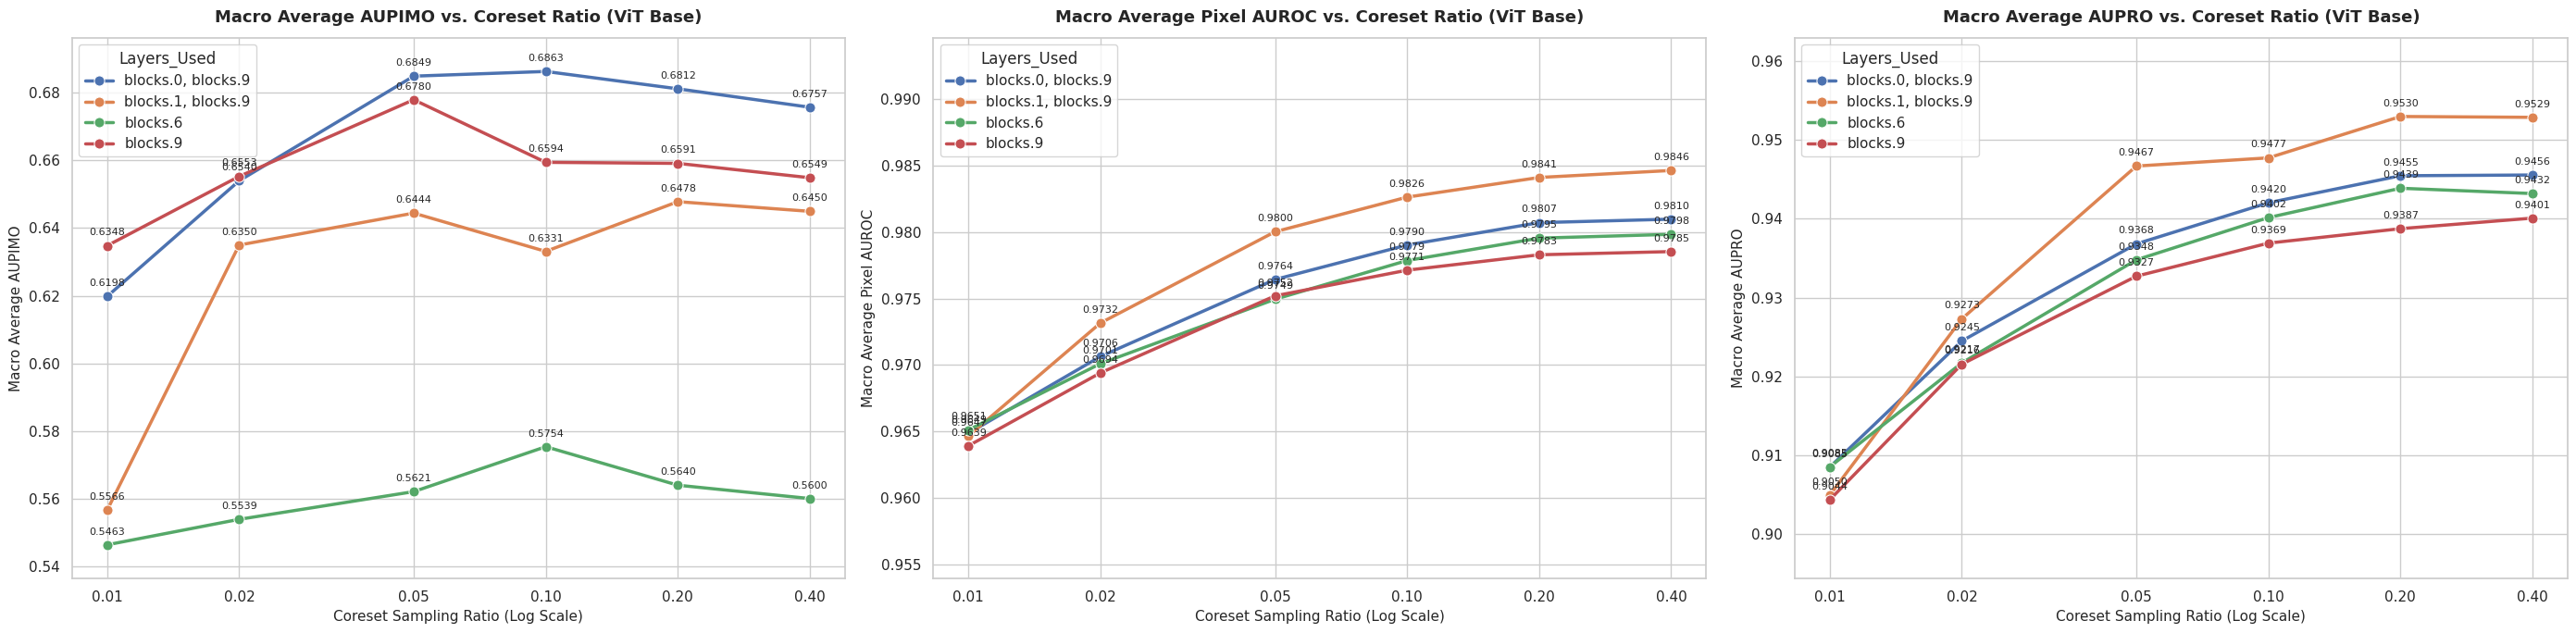

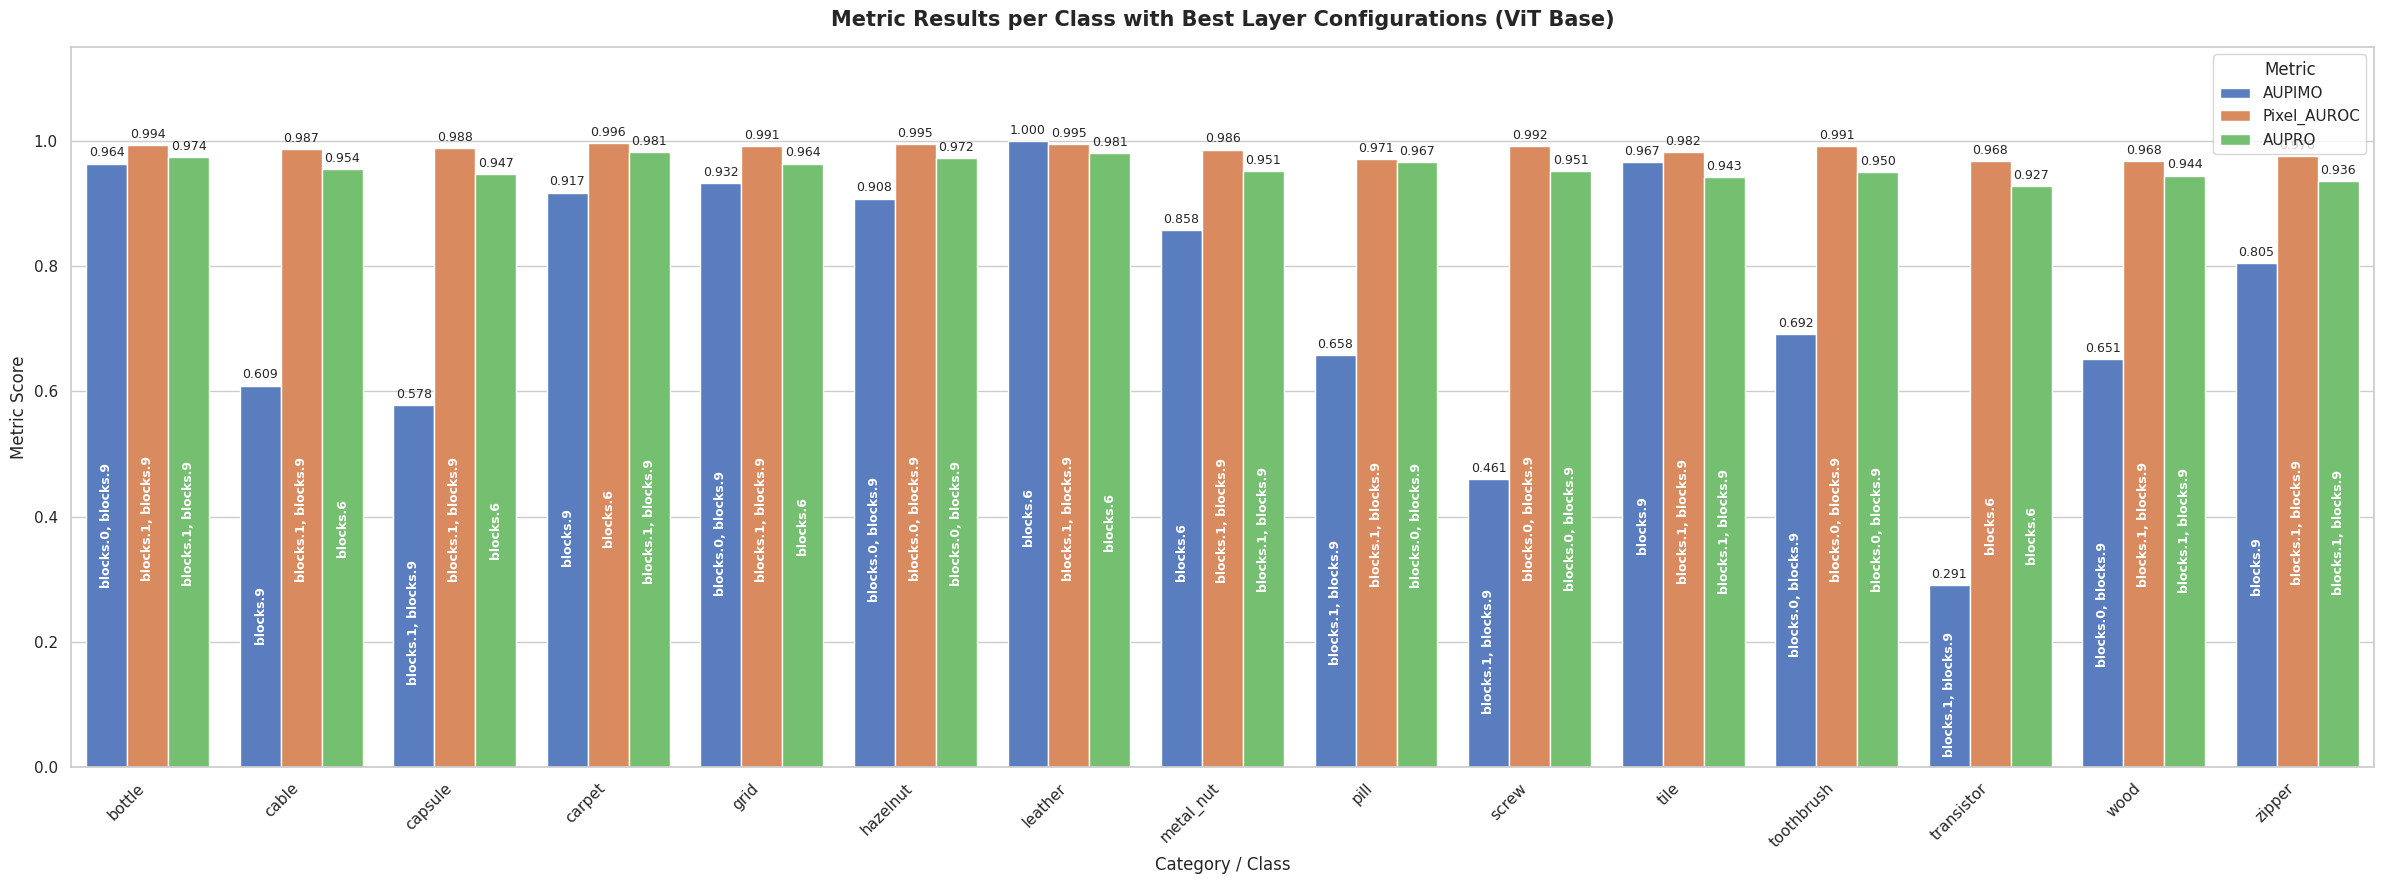

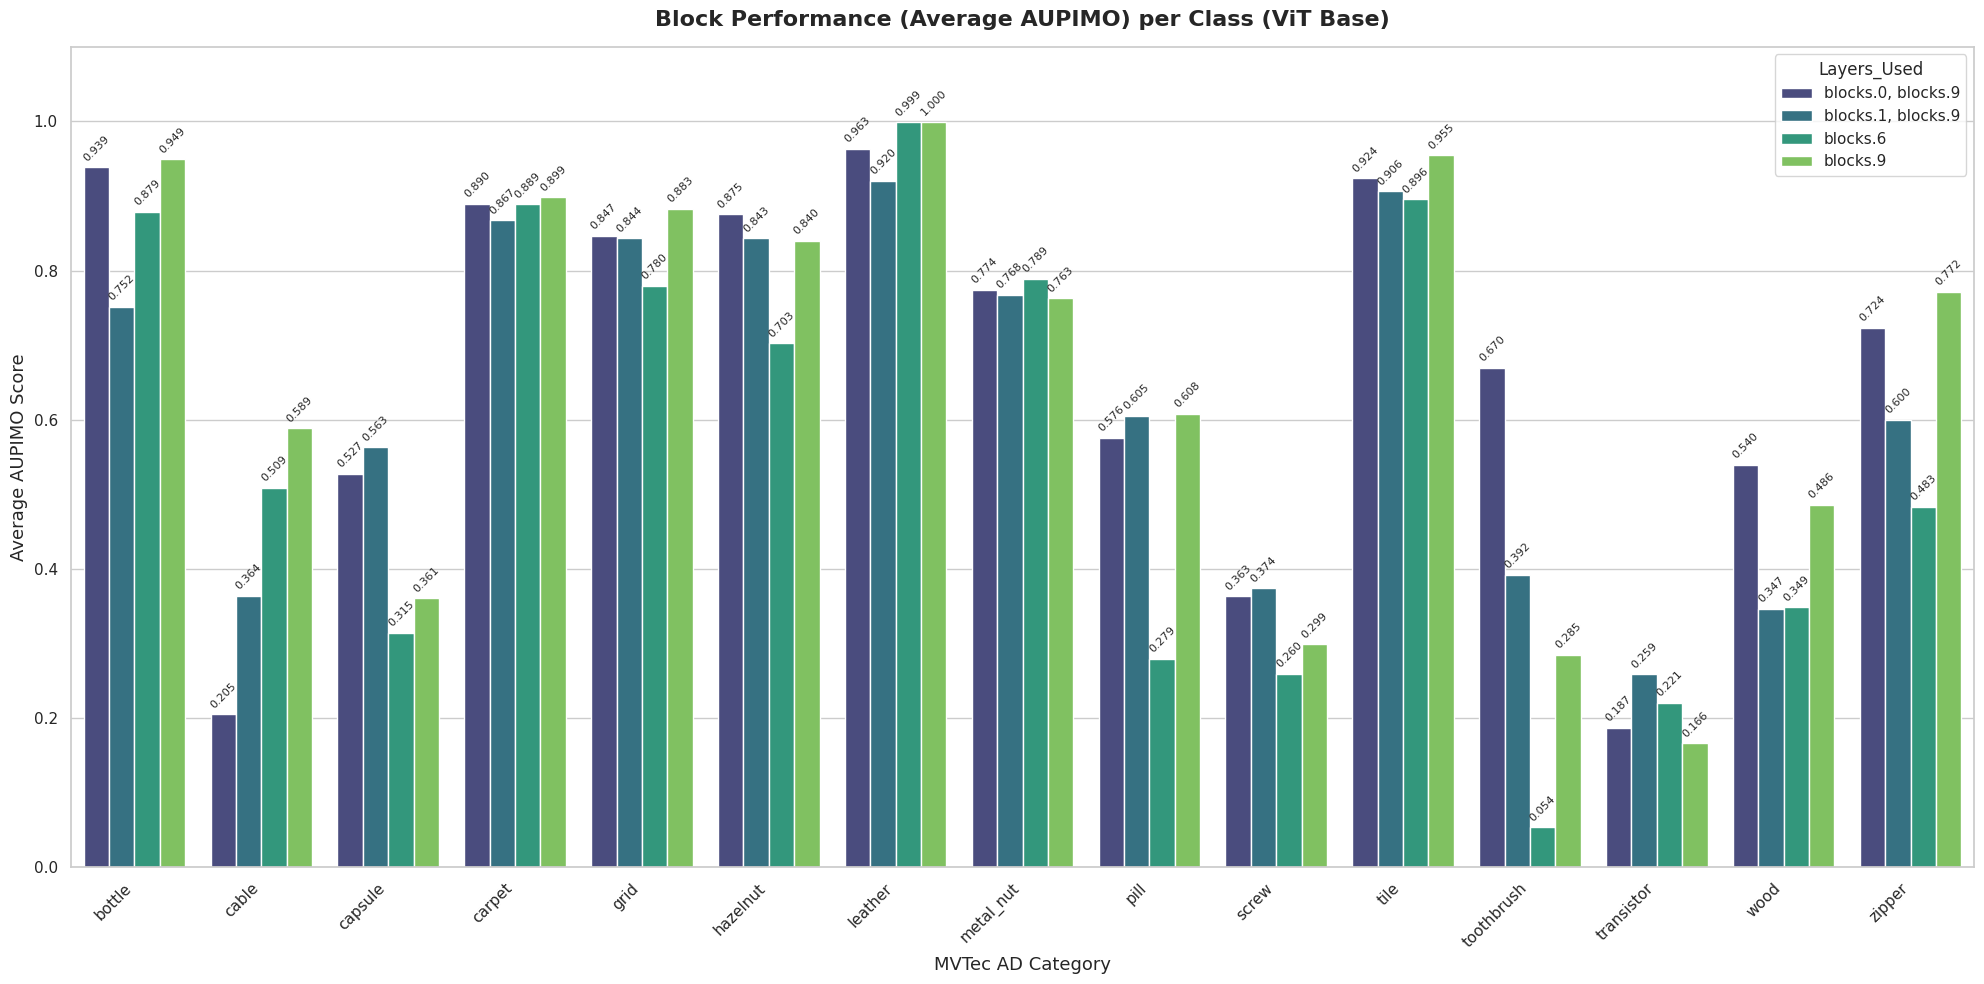

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive', force_remount=False)

# 2. Path to the ViT Base dataset
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_gridsearch_vit_base_coreset_copy.xlsx")
if not excel_log_path.exists():
    raise FileNotFoundError(f"Could not find the log file at: {excel_log_path}")

# 3. Load dataset
df = pd.read_excel(excel_log_path)

# 4. Standardize and clean category names
category_col = "Category" if "Category" in df.columns else "Class"
df["Clean_Category"] = df[category_col].astype(str).str.replace(" texture", "").str.replace(" object", "")

# 5. Extract latest runs
group_cols = ["Clean_Category", "Coreset_Ratio", "Layers_Used"] if "Coreset_Ratio" in df.columns else ["Clean_Category", "Layers_Used"]
latest_runs = df.sort_values("Timestamp").groupby(group_cols).last().reset_index() if "Timestamp" in df.columns else df

# 6. Plot 1: Macro Average vs Coreset Ratio (if multiple coreset ratios exist)
if "Coreset_Ratio" in latest_runs.columns and latest_runs["Coreset_Ratio"].nunique() > 1:
    macro_summary = latest_runs.groupby(["Coreset_Ratio", "Layers_Used"])[["AUPIMO", "Pixel_AUROC", "AUPRO"]].mean().reset_index()
    sns.set_theme(style="whitegrid")
    metrics_to_plot = [
        ("AUPIMO", "Macro Average AUPIMO"),
        ("Pixel_AUROC", "Macro Average Pixel AUROC"),
        ("AUPRO", "Macro Average AUPRO")
    ]
    fig, axes = plt.subplots(1, 3, figsize=(28, 7))
    for idx, (col_name, label) in enumerate(metrics_to_plot):
        ax = axes[idx]
        sns.lineplot(data=macro_summary, x="Coreset_Ratio", y=col_name, hue="Layers_Used", marker="o", linewidth=2.5, markersize=8, ax=ax)
        ax.set_title(f"{label} vs. Coreset Ratio (ViT Base)", fontsize=13, fontweight="bold", pad=12)
        ax.set_xlabel("Coreset Sampling Ratio (Log Scale)", fontsize=11)
        ax.set_ylabel(label, fontsize=11)
        ax.set_xscale('log')
        ratios = sorted(macro_summary["Coreset_Ratio"].unique())
        ax.set_xticks(ratios)
        ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
        min_val, max_val = macro_summary[col_name].min(), macro_summary[col_name].max()
        ax.set_ylim(min_val - 0.01, min(max_val + 0.01, 1.0))
        for layers in macro_summary["Layers_Used"].unique():
            subset_df = macro_summary[macro_summary["Layers_Used"] == layers]
            for x, y in zip(subset_df["Coreset_Ratio"], subset_df[col_name]):
                ax.annotate(f"{y:.4f}", (x, y), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping Coreset Ratio line plot because only one Coreset Ratio was used or column is missing.")

# 7. Plot 2: Best Configurations Per Class
best_configs = {}
for metric in ["AUPIMO", "Pixel_AUROC", "AUPRO"]:
    if metric in latest_runs.columns:
        idx_max = latest_runs.groupby("Clean_Category")[metric].idxmax()
        best_rows = latest_runs.loc[idx_max]
        for _, row in best_rows.iterrows():
            best_configs[(row["Clean_Category"], metric)] = {
                "score": row[metric],
                "block": row["Layers_Used"]
            }

class_summary = latest_runs.groupby("Clean_Category")[["AUPIMO", "Pixel_AUROC", "AUPRO"]].max().reset_index()
melted_class = class_summary.melt(id_vars="Clean_Category", value_vars=["AUPIMO", "Pixel_AUROC", "AUPRO"], var_name="Metric", value_name="Score")

plt.figure(figsize=(24, 9))
ax = sns.barplot(data=melted_class, x="Clean_Category", y="Score", hue="Metric", palette="muted")
plt.title("Metric Results per Class with Best Layer Configurations (ViT Base)", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Category / Class", fontsize=12)
plt.ylabel("Metric Score", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.ylim(0.0, 1.15)

categories = sorted(melted_class["Clean_Category"].unique())
metrics = ["AUPIMO", "Pixel_AUROC", "AUPRO"]
num_categories = len(categories)

for i, p in enumerate(ax.patches):
    height = p.get_height()
    if height > 0:
        metric_idx = i // num_categories
        category_idx = i % num_categories
        metric_name = metrics[metric_idx]
        category_name = categories[category_idx]
        best_info = best_configs.get((category_name, metric_name), {"score": height, "block": "N/A"})
        block_label = best_info["block"]
        ax.annotate(f"{height:.3f}", (p.get_x() + p.get_width() / 2., height), ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')
        ax.annotate(str(block_label), (p.get_x() + p.get_width() / 2., height * 0.40), ha='center', va='center', color='white', fontsize=9, fontweight='bold', rotation=90)

plt.tight_layout()
plt.show()

# 8. Plot 3: Block Performance (Average AUPIMO) per Class
if "AUPIMO" in latest_runs.columns:
    block_perf = latest_runs.groupby(["Clean_Category", "Layers_Used"])["AUPIMO"].mean().reset_index()
    plt.figure(figsize=(20, 10))
    ax = sns.barplot(data=block_perf, x="Clean_Category", y="AUPIMO", hue="Layers_Used", palette="viridis")
    plt.title("Block Performance (Average AUPIMO) per Class (ViT Base)", fontsize=16, fontweight="bold", pad=15)
    plt.xlabel("MVTec AD Category", fontsize=13)
    plt.ylabel("Average AUPIMO Score", fontsize=13)
    plt.xticks(rotation=45, ha="right")
    plt.ylim(0.0, 1.1)
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.annotate(f"{height:.3f}", (p.get_x() + p.get_width() / 2., height), ha='center', va='bottom', fontsize=8, xytext=(0, 3), textcoords='offset points', rotation=45)
    plt.tight_layout()
    plt.show()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


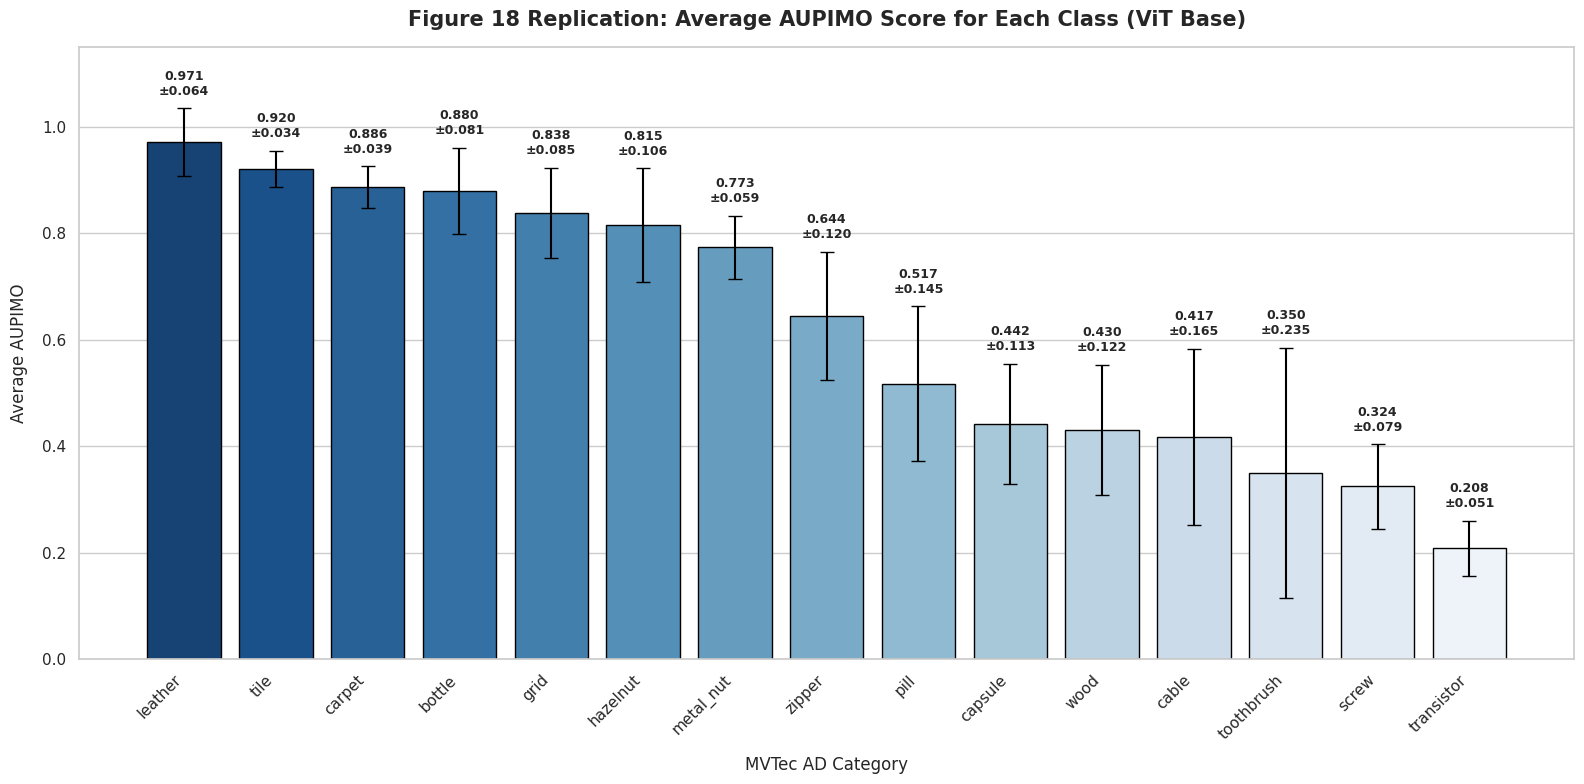

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import drive

# 1. Mount Google Drive safely
drive.mount('/content/drive', force_remount=False)

# 2. Path to the ViT Base dataset
excel_log_path = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_gridsearch_vit_base_coreset_copy.xlsx")
if not excel_log_path.exists():
    raise FileNotFoundError(f"Could not find the log file at: {excel_log_path}")

# 3. Load dataset
df_base = pd.read_excel(excel_log_path)

# 4. Standardize and clean category names
category_col = "Category" if "Category" in df_base.columns else "Class"
df_base["Clean_Category"] = df_base[category_col].astype(str).str.replace(" texture", "").str.replace(" object", "")

# 5. Extract latest runs
group_cols = ["Clean_Category", "Coreset_Ratio", "Layers_Used"] if "Coreset_Ratio" in df_base.columns else ["Clean_Category", "Layers_Used"]
latest_runs_base = df_base.sort_values("Timestamp").groupby(group_cols).last().reset_index() if "Timestamp" in df_base.columns else df_base

# 6. Calculate Average AUPIMO and Std Dev for each category across all configurations
class_aupimo_stats_base = latest_runs_base.groupby("Clean_Category")["AUPIMO"].agg(Mean_AUPIMO="mean", Std_AUPIMO="std").reset_index()
class_aupimo_stats_base = class_aupimo_stats_base.sort_values(by="Mean_AUPIMO", ascending=False)

# 7. Create Visualization mimicking Figure 18 style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 8))

# Create bar plot
ax = sns.barplot(
    data=class_aupimo_stats_base,
    x="Clean_Category",
    y="Mean_AUPIMO",
    hue="Clean_Category",
    palette="Blues_r",
    edgecolor="black",
    legend=False
)

# Add the error bars manually
x_coords = range(len(class_aupimo_stats_base))
plt.errorbar(
    x=x_coords,
    y=class_aupimo_stats_base["Mean_AUPIMO"],
    yerr=class_aupimo_stats_base["Std_AUPIMO"].fillna(0),
    fmt='none',
    color='black',
    capsize=5,
    elinewidth=1.5
)

plt.title("Figure 18 Replication: Average AUPIMO Score for Each Class (ViT Base)", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("MVTec AD Category", fontsize=12, labelpad=10)
plt.ylabel("Average AUPIMO", fontsize=12, labelpad=10)
plt.xticks(ticks=x_coords, labels=class_aupimo_stats_base["Clean_Category"], rotation=45, ha="right", fontsize=11)
plt.ylim(0.0, 1.15)

# Annotate values
for idx, p in enumerate(ax.patches):
    height = p.get_height()
    mean_val = class_aupimo_stats_base.iloc[idx]["Mean_AUPIMO"]
    std_val = class_aupimo_stats_base.iloc[idx]["Std_AUPIMO"]
    std_val = std_val if not pd.isna(std_val) else 0.0
    ax.annotate(
        f"{mean_val:.3f}\n±{std_val:.3f}",
        (p.get_x() + p.get_width() / 2., max(height, mean_val + std_val) + 0.02),
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


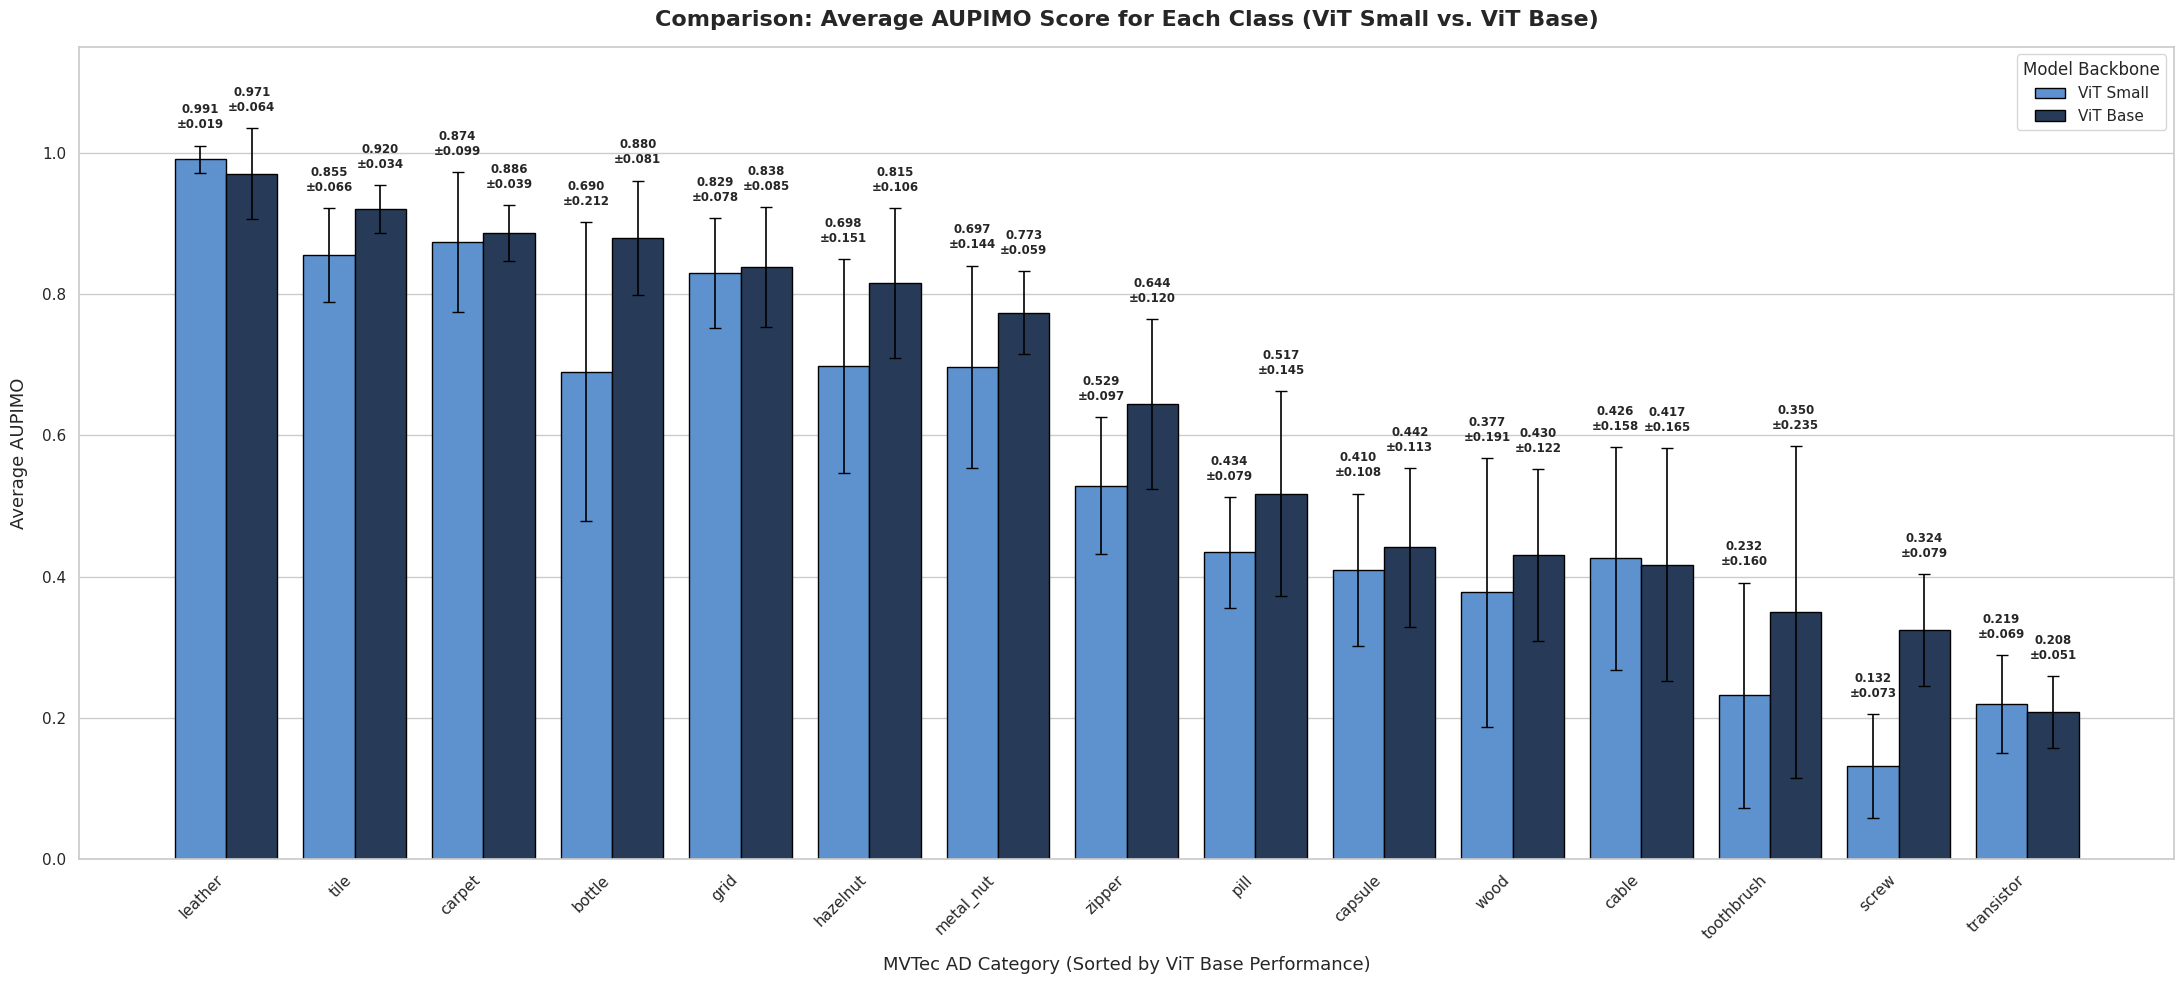

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive', force_remount=False)

# 2. Define file paths
path_small = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_gridsearch_vit_small_coreset.xlsx")
path_base = Path("/content/drive/MyDrive/anomalib_experiments/patchcore_gridsearch_vit_base_coreset_copy.xlsx")

if not path_small.exists() or not path_base.exists():
    raise FileNotFoundError("Please make sure both ViT Small and ViT Base spreadsheets exist.")

# 3. Load datasets
df_small = pd.read_excel(path_small)
df_base = pd.read_excel(path_base)

# 4. Standardize and clean category names
for df in [df_small, df_base]:
    cat_col = "Category" if "Category" in df.columns else "Class"
    df["Clean_Category"] = df[cat_col].astype(str).str.replace(" texture", "").str.replace(" object", "")

# 5. Extract latest configurations
group_cols_s = ["Clean_Category", "Coreset_Ratio", "Layers_Used"] if "Coreset_Ratio" in df_small.columns else ["Clean_Category", "Layers_Used"]
group_cols_b = ["Clean_Category", "Coreset_Ratio", "Layers_Used"] if "Coreset_Ratio" in df_base.columns else ["Clean_Category", "Layers_Used"]

latest_small = df_small.sort_values("Timestamp").groupby(group_cols_s).last().reset_index() if "Timestamp" in df_small.columns else df_small
latest_base = df_base.sort_values("Timestamp").groupby(group_cols_b).last().reset_index() if "Timestamp" in df_base.columns else df_base

# 6. Calculate Average AUPIMO and Std Dev
stats_small = latest_small.groupby("Clean_Category")["AUPIMO"].agg(Mean_AUPIMO="mean", Std_AUPIMO="std").reset_index()
stats_small["Model"] = "ViT Small"

stats_base = latest_base.groupby("Clean_Category")["AUPIMO"].agg(Mean_AUPIMO="mean", Std_AUPIMO="std").reset_index()
stats_base["Model"] = "ViT Base"

# 7. Merge datasets for comparison
combined_stats = pd.concat([stats_small, stats_base], ignore_index=True)
combined_stats["Std_AUPIMO"] = combined_stats["Std_AUPIMO"].fillna(0)

# Sort categories based on ViT Base's mean performance descending
sort_order = stats_base.sort_values(by="Mean_AUPIMO", ascending=False)["Clean_Category"].tolist()
combined_stats["Clean_Category"] = pd.Categorical(combined_stats["Clean_Category"], categories=sort_order, ordered=True)
combined_stats = combined_stats.sort_values("Clean_Category")

# 8. Visualization
sns.set_theme(style="whitegrid")
plt.figure(figsize=(22, 10))

ax = sns.barplot(
    data=combined_stats,
    x="Clean_Category",
    y="Mean_AUPIMO",
    hue="Model",
    palette=["#4A90E2", "#1F3A60"],
    edgecolor="black"
)

# Add customized error bars manually
x_coords = np.arange(len(sort_order))
width = 0.4 # width of the bars

small_data = combined_stats[combined_stats["Model"] == "ViT Small"]
base_data = combined_stats[combined_stats["Model"] == "ViT Base"]

# Error bars for ViT Small (left bar)
plt.errorbar(
    x=x_coords - width/2,
    y=small_data["Mean_AUPIMO"],
    yerr=small_data["Std_AUPIMO"],
    fmt='none',
    color='black',
    capsize=4,
    elinewidth=1.2
)

# Error bars for ViT Base (right bar)
plt.errorbar(
    x=x_coords + width/2,
    y=base_data["Mean_AUPIMO"],
    yerr=base_data["Std_AUPIMO"],
    fmt='none',
    color='black',
    capsize=4,
    elinewidth=1.2
)

plt.title("Comparison: Average AUPIMO Score for Each Class (ViT Small vs. ViT Base)", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("MVTec AD Category (Sorted by ViT Base Performance)", fontsize=13, labelpad=10)
plt.ylabel("Average AUPIMO", fontsize=13, labelpad=10)
plt.xticks(ticks=x_coords, labels=sort_order, rotation=45, ha="right", fontsize=11)
plt.ylim(0.0, 1.15)
plt.legend(title="Model Backbone", fontsize=11, title_fontsize=12, loc="upper right")

# Annotate scores above bars
for idx, p in enumerate(ax.patches):
    height = p.get_height()
    if height > 0:
        # Determine model subset
        is_base = idx >= len(sort_order)
        sub_data = base_data if is_base else small_data
        cat_idx = idx % len(sort_order)
        row = sub_data.iloc[cat_idx]
        mean_val = row["Mean_AUPIMO"]
        std_val = row["Std_AUPIMO"]

        ax.annotate(
            f"{mean_val:.3f}\n±{std_val:.3f}",
            (p.get_x() + p.get_width() / 2., max(height, mean_val + std_val) + 0.02),
            ha='center',
            va='bottom',
            fontsize=8.5,
            fontweight='bold'
        )

plt.tight_layout()
plt.show()